# 01 drop test

Scan of a dog figurine -> MuJoCo rigid body -> drop it on the floor. The scan and cameras come from the lab's reconstruction project (not in this repo).

## Settings

In [14]:
from pathlib import Path
import csv

import numpy as np
import trimesh
import coacd
import mujoco
import matplotlib.pyplot as plt

SCAN_DIR = Path.home() / 'Documents/bd3d-reconstruction-quality/results/gpu-pilot-d8/ref50'
MESH_PATH = SCAN_DIR / 'raw-mesh.obj'
CAMERAS_PATH = SCAN_DIR / 'cameras.csv'
ASSET_DIR = Path('assets')

CUT = 0.19                  # fraction of scan height
ASSUMED_H = 0.20            # m, assumed
DENSITY = 1500              # kg/m^3, assumed
FRICTION = 0.8
DROP_HEIGHT = 0.3           # m
DROP_TILT_DEG = (15, 10, 0)
COACD_THRESHOLD = 0.08
SIM_SECONDS = 3.0

## Load the scan

Straight out of Metashape. Units are arbitrary and it isn't watertight.

In [15]:
mesh = trimesh.load(MESH_PATH, force='mesh')
print('vertices:', len(mesh.vertices))
print('faces:   ', len(mesh.faces))
print('bounding box size (Metashape units):', mesh.extents)
print('watertight (closed surface)?', mesh.is_watertight)

vertices: 10916
faces:    21759
bounding box size (Metashape units): [2.863455 2.212346 2.648704]
watertight (closed surface)? False


## Remove floaters

Keep the largest connected piece. The rest is reconstruction noise.

In [16]:
pieces = mesh.split(only_watertight=False)
print('connected pieces:', len(pieces))
for i, p in enumerate(pieces):
    print(f'piece {i}: {len(p.faces)} faces, area {p.area:.4f}')
dog = max(pieces, key=lambda p: p.area)

connected pieces: 4
piece 0: 21611 faces, area 11.2409
piece 1: 86 faces, area 0.0201
piece 2: 56 faces, area 0.0045
piece 3: 6 faces, area 0.0002


## Find up and orient

The cameras were in a ring around the dog, so the ring's normal is vertical. That's the PCA direction with the smallest variance. Flip it so it points toward the cameras, rotate it to +z, then put the lowest point at z = 0 and centre x/y.

In [17]:
with open(CAMERAS_PATH) as f:
    cam_pos = np.array([[float(r['x']), float(r['y']), float(r['z'])]
                        for r in csv.DictReader(f) if r['x']])   # skip unaligned cameras

evals, evecs = np.linalg.eigh(np.cov((cam_pos - cam_pos.mean(0)).T))
up = evecs[:, 0]   # smallest eigenvalue
if (cam_pos.mean(0) - dog.centroid) @ up < 0:
    up = -up

rotation = trimesh.geometry.align_vectors(up, [0, 0, 1])
dog.apply_transform(rotation)
dog.apply_translation(-dog.bounds[0] * [0, 0, 1] - dog.centroid * [1, 1, 0])

print('extents after orienting (x, y, z):', dog.extents)
dog.show()

extents after orienting (x, y, z): [2.67482746 2.94545425 1.92275969]


## Cut off the base

The dog was scanned on a platform. Surface area per height bin shows where it is: the platform top is flat, so all its area lands in one bin (the spike at 0.13-0.17). The sides are spread over many bins. Cut just above the spike.

In [18]:
face_z = dog.triangles_center[:, 2]
height = dog.extents[2]
hist, edges = np.histogram(face_z / height, bins=20, weights=dog.area_faces)
for lo, hi, area in zip(edges[:-1], edges[1:], hist):
    print(f'{lo:.2f}–{hi:.2f} of height: {"#" * int(60 * area / hist.max())}')

0.03–0.08 of height: #
0.08–0.13 of height: ####
0.13–0.17 of height: ############################################################
0.17–0.22 of height: #######
0.22–0.27 of height: ######
0.27–0.32 of height: #####
0.32–0.37 of height: #####
0.37–0.42 of height: #####
0.42–0.47 of height: #####
0.47–0.51 of height: #####
0.51–0.56 of height: #####
0.56–0.61 of height: #####
0.61–0.66 of height: #####
0.66–0.71 of height: ###
0.71–0.76 of height: ###
0.76–0.81 of height: ###
0.81–0.85 of height: ###
0.85–0.90 of height: ###
0.90–0.95 of height: #
0.95–1.00 of height: 


In [19]:
cut_z = dog.bounds[0, 2] + CUT * dog.extents[2]
body = trimesh.intersections.slice_mesh_plane(
    dog, plane_normal=[0, 0, 1], plane_origin=[0, 0, cut_z])
print('faces after cut:', len(body.faces))

faces after cut: 14101


## Set scale

The scan has no real size, so the height (0.20 m) and density (1500 kg/m³) are assumptions. For a robot this matters a lot (gripper width, payload, forces). For a drop it barely does, since gravity accelerates everything equally and tipping depends on shape, not size.

In [20]:
# bottom-centre to the origin, so scaling keeps it on the floor
body.apply_translation([-body.centroid[0], -body.centroid[1], -body.bounds[0, 2]])
body.apply_scale(ASSUMED_H / body.extents[2])

print('faces:', len(body.faces))
print('size (m):', body.extents.round(3))
print('watertight?', body.is_watertight)
body.show()

faces: 14101
size (m): [0.174 0.247 0.2  ]
watertight? False


## Collision geometry (CoACD)

The visual mesh is the detailed scan; it's only drawn. Physics uses convex pieces, because MuJoCo collides with each mesh's convex hull, and one hull around the whole dog would fill in the gaps between the legs. CoACD warns "Unclosed mesh" because the scan has holes and the cut left the bottom open, so it remeshes it closed first. Lower threshold means more, tighter pieces but slower. 0.08 gives 67.

In [21]:
ASSET_DIR.mkdir(exist_ok=True)
body.export(ASSET_DIR / 'dog_visual.obj')

coacd.set_log_level('error')
parts = coacd.run_coacd(coacd.Mesh(body.vertices, body.faces), threshold=COACD_THRESHOLD)
for i, (verts, faces) in enumerate(parts):
    trimesh.Trimesh(verts, faces).export(ASSET_DIR / f'hull_{i}.obj')
print('convex pieces:', len(parts))

convex pieces: 67


## MuJoCo scene

- meshes in `<asset>`: one visual, one per hull
- floor: a static plane
- `freejoint`: lets the dog move in all 6 DOF
- visual geom: no collision (`contype/conaffinity=0`), no mass (`density=0`)
- hull geoms: give mass via density and set friction; invisible
- saved as `assets/scene.xml`, so `python view.py drop` can open it

In [22]:
mesh_assets = '\n'.join(f'<mesh name="h{i}" file="hull_{i}.obj"/>'
                        for i in range(len(parts)))
hull_geoms = '\n'.join(f'<geom type="mesh" mesh="h{i}" density="{DENSITY}" friction="{FRICTION}" rgba="1 0 0 0"/>'
                       for i in range(len(parts)))
tilt = ' '.join(str(a) for a in DROP_TILT_DEG)
xml = f'''
<mujoco>
  <asset>
    <mesh name="vis" file="dog_visual.obj" inertia="shell"/>
    {mesh_assets}
  </asset>
  <worldbody>
    <light pos="0 0 2"/>
    <geom type="plane" size="1 1 .1" rgba=".8 .8 .8 1"/>
    <body name="dog" pos="0 0 {DROP_HEIGHT}" euler="{tilt}">
      <freejoint/>
      <geom type="mesh" mesh="vis" contype="0" conaffinity="0" density="0" rgba=".6 .5 .4 1"/>
      {hull_geoms}
    </body>
  </worldbody>
</mujoco>'''
(ASSET_DIR / 'scene.xml').write_text(xml)   # mesh paths are relative to this file; view.py opens it
model = mujoco.MjModel.from_xml_path(str(ASSET_DIR / 'scene.xml'))
data = mujoco.MjData(model)
print(f'mass: {model.body_mass[1]*1000:.0f} g')   # body 0 is the world

mass: 1121 g


## Simulate

Height of origin = `qpos[2]`, the dog's bottom-centre. Tilt comes from the quaternion (w, x, y, z): 1 - 2(x² + y²) is cos of the angle between the dog's up axis and world up. Default timestep is 0.002 s.

final height of origin: 0.1 cm, final tilt: 0.0 deg
stayed upright


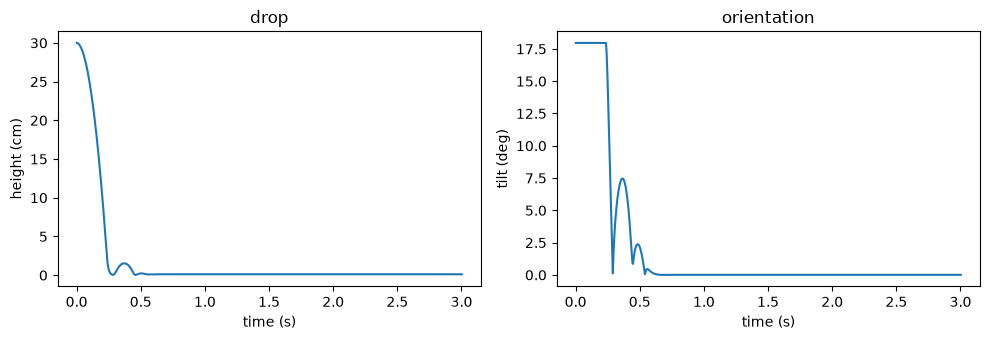

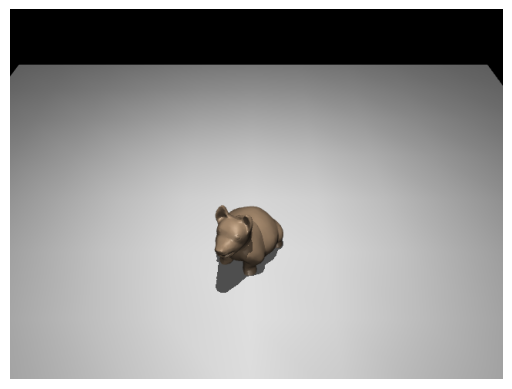

In [23]:
times, heights, tilts = [], [], []
while data.time < SIM_SECONDS:
    mujoco.mj_step(model, data)
    q = data.qpos[3:7]
    up_z = 1 - 2 * (q[1]**2 + q[2]**2)   # cos(tilt)
    times.append(data.time)
    heights.append(data.qpos[2])
    tilts.append(np.degrees(np.arccos(np.clip(up_z, -1, 1))))

print(f'final height of origin: {heights[-1]*100:.1f} cm, final tilt: {tilts[-1]:.1f} deg')
print('tipped over' if tilts[-1] > 45 else 'stayed upright')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(times, np.array(heights)*100); ax[0].set(xlabel='time (s)', ylabel='height (cm)', title='drop')
ax[1].plot(times, tilts); ax[1].set(xlabel='time (s)', ylabel='tilt (deg)', title='orientation')
plt.tight_layout(); plt.show()
try:
    renderer = mujoco.Renderer(model, 480, 640)
    renderer.update_scene(data)
    plt.imshow(renderer.render()); plt.axis('off'); plt.show()
except Exception as e:
    print('render skipped:', e)

## Sanity check

Before it hits the floor it's in free fall, so contact time should be about sqrt(2h/g), with h = lowest hull point at t = 0. Runs on a separate copy so it doesn't touch the results above.

In [24]:
check = mujoco.MjData(model)
mujoco.mj_forward(model, check)

# lowest hull vertex in world coordinates at t = 0
lowest = np.inf
for g in range(model.ngeom):
    if model.geom_type[g] != mujoco.mjtGeom.mjGEOM_MESH or not model.geom_contype[g]:
        continue
    mesh_id = model.geom_dataid[g]
    start, n = model.mesh_vertadr[mesh_id], model.mesh_vertnum[mesh_id]
    world = check.geom_xpos[g] + model.mesh_vert[start:start + n] @ check.geom_xmat[g].reshape(3, 3).T
    lowest = min(lowest, world[:, 2].min())

while check.ncon == 0:
    mujoco.mj_step(model, check)

g = -model.opt.gravity[2]   # m/s^2
print(f'h = {lowest*100:.1f} cm')
print(f'sim: {check.time:.3f} s, sqrt(2h/g): {np.sqrt(2 * lowest / g):.3f} s')

h = 27.5 cm
sim: 0.238 s, sqrt(2h/g): 0.237 s


## Results and limitations

4 pieces, cut at 0.19, 67 hulls, 1121 g, final tilt 0.0 deg, stayed upright. Contact at 0.238 s vs 0.237 s predicted.

- Height and density are assumed, so the mass is too (and it assumes a solid dog).
- The scan has holes; CoACD guesses the closed shape.
- The flat cut bottom makes staying upright pretty much guaranteed. Drops from random orientations, and the comparison with a worse reconstruction, are in notebook 02.